# Chapitre 7 - Exercices 7.6 à 7.10

* **7.6** : le nombre effectif de paramètres des $k$ plus proches voisins vaut $N/k$ ;
* **7.7** : le lien entre $C_p$/AIC et la validation croisée généralisée ;
* **7.8** : la famille $\{I(\sin(\alpha x) > 0)\}$ a une dimension VC infinie ;
* **7.9** : sélection du meilleur sous-ensemble sur les données de cancer de la prostate
  par AIC, BIC, validation croisée et bootstrap .632 ;
* **7.10** : la validation croisée avec des prédicteurs binaires très nombreux.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch07_selection as sel
set_style()

## Exercice 7.6 : Degrés de liberté des $k$ plus proches voisins

**Énoncé.** Montrer que, pour un modèle à erreur additive, le nombre effectif de
paramètres de l'ajustement par les $k$ plus proches voisins est $N/k$.

**Rappels.** Le nombre effectif de paramètres est défini par (7.33) :
$\mathrm{df}(\hat{\mathbf y}) = \sum_i\mathrm{Cov}(\hat y_i, y_i)/\sigma^2_\varepsilon$, et vaut
$\mathrm{trace}(\mathbf S)$ pour un lisseur linéaire $\hat{\mathbf y} = \mathbf S\mathbf y$
(exercice 7.5). On suppose les $x_i$ fixés et **distincts**, et l'on note $N_k(x_i)$ les
indices des $k$ points d'apprentissage les plus proches de $x_i$.

**Solution.** Aux points d'apprentissage, l'ajustement s'écrit
$\hat y_i = \frac1k\sum_{j\in N_k(x_i)}y_j$ : c'est un lisseur linéaire de matrice
$S_{ij} = \frac1k I(j\in N_k(x_i))$, qui ne dépend que des $x$. Or $x_i$ est à distance
nulle de lui-même : c'est son propre plus proche voisin, donc $i\in N_k(x_i)$ et
$S_{ii} = 1/k$ pour tout $i$. Ainsi

$$\mathrm{df} = \mathrm{trace}(\mathbf S) = \sum_{i=1}^N\frac1k = \frac Nk.$$

Directement avec (7.33) : les $y_j$ étant indépendants,
$\mathrm{Cov}(\hat y_i, y_i) = \frac1k\sum_{j\in N_k(x_i)}\mathrm{Cov}(y_j, y_i) = \frac1k\mathrm{Var}(y_i) = \frac{\sigma^2_\varepsilon}k$,
et la somme sur $i$ divisée par $\sigma^2_\varepsilon$ redonne $N/k$. $\square$

> **Intuition.** Si les $N$ points se répartissaient en $N/k$ groupes disjoints de $k$
> voisins, les $k$-PPV ajusteraient une constante par groupe : $N/k$ paramètres. La formule
> reste vraie même si les voisinages se chevauchent.

**Vérification numérique** : trace de $\mathbf S$ et estimation par simulation de la
covariance, pour $N = 60$ points de $\mathbb R^2$.

In [2]:
rng = np.random.RandomState(0)
N = 60
X = rng.rand(N, 2)
f = np.sin(3 * X[:, 0]) + X[:, 1]
ks = [1, 2, 3, 4, 5, 6, 10, 12, 15, 20, 30, 60]
df_tr, df_mc = [], []
for k in ks:
    S = sel.knn_smoother_matrix(X, k)
    df_tr.append(sel.df_trace(S))
    df_mc.append(sel.df_monte_carlo(lambda y: sel.knn_regression(X, y, X, k), f, 0.7, n_rep=1500, rng=rng))

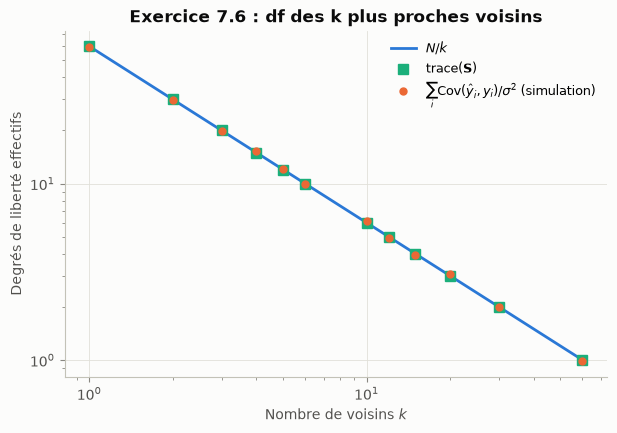

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
kk = np.linspace(1, 60, 300)
ax.plot(kk, N / kk, color=BLUE, label="$N/k$")
ax.plot(ks, df_tr, "s", color=COLORS[2], ms=7, label=r"$\mathrm{trace}(\mathbf{S})$")
ax.plot(ks, df_mc, "o", color=ORANGE, label=r"$\sum_i \mathrm{Cov}(\hat y_i, y_i)/\sigma^2$ (simulation)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Nombre de voisins $k$")
ax.set_ylabel("Degrés de liberté effectifs")
ax.set_title("Exercice 7.6 : df des k plus proches voisins")
ax.legend()
plt.show()

> **À retenir.** Pour les $k$-PPV, $S_{ii} = 1/k$ (chaque point est son propre voisin),
> donc $\mathrm{df} = N/k$ : la complexité est inversement proportionnelle à $k$. C'est la
> valeur utilisée pour AIC/BIC dans les figures 7.7 du livre.

## Exercice 7.7 : Relation entre $C_p$/AIC et GCV

**Énoncé.** À l'aide de l'approximation $1/(1-x)^2\approx 1 + 2x$, mettre en évidence la
relation entre $C_p$/AIC (7.26) et la validation croisée généralisée (7.52), la
principale différence étant le modèle utilisé pour estimer la variance du bruit
$\sigma^2_\varepsilon$.

**Rappels.** Pour un lisseur linéaire de degrés de liberté $\mathrm{df} = \mathrm{trace}(\mathbf S)$,
avec $\overline{\mathrm{err}} = \frac1N\sum_i(y_i - \hat f(x_i))^2$ :

$$C_p = \overline{\mathrm{err}} + 2\,\frac{\mathrm{df}}N\,\hat\sigma^2_\varepsilon,
\qquad
\mathrm{GCV} = \frac{\overline{\mathrm{err}}}{\big(1 - \mathrm{df}/N\big)^2}.$$

**Approximation.** Par développement limité de $u\mapsto(1-u)^{-2}$ en $0$ (dérivée
$2(1-u)^{-3}$, qui vaut $2$ en $0$) : $(1-u)^{-2} = 1 + 2u + O(u^2)$. Avec $u = \mathrm{df}/N$
petit (peu de paramètres devant $N$) :

$$\mathrm{GCV}\approx\overline{\mathrm{err}}\Big(1 + 2\frac{\mathrm{df}}N\Big) = \overline{\mathrm{err}} + 2\,\frac{\mathrm{df}}N\,\overline{\mathrm{err}}.$$

**Comparaison.** GCV a donc (au premier ordre) **exactement la forme de $C_p$**, mais avec
$\hat\sigma^2_\varepsilon$ remplacé par $\overline{\mathrm{err}}$, l'erreur d'apprentissage
**du modèle évalué lui-même**. En $C_p$, on estime $\sigma^2_\varepsilon$ une fois pour toutes
à partir d'un modèle peu biaisé (souvent le plus complexe), et la même valeur sert pour
tous les modèles comparés. En GCV, l'estimation change avec le modèle :

* pour un modèle très lisse (biaisé), $\overline{\mathrm{err}}$ surestime $\sigma^2_\varepsilon$ ;
* pour un modèle très flexible, $\overline{\mathrm{err}}$ sous-estime $\sigma^2_\varepsilon$
  (d'un facteur $\approx 1 - \mathrm{df}/N$), mais le facteur exact $(1 - \mathrm{df}/N)^{-2}$
  compense largement.

**Illustration** avec une spline de lissage ($N = 100$) : on trace GCV, son approximation
au premier ordre et $C_p$ avec $\hat\sigma^2_\varepsilon$ tiré d'un ajustement peu biaisé
($\mathrm{df}\approx 30$, $\hat\sigma^2 = N\,\overline{\mathrm{err}}/(N - \mathrm{df})$).

In [4]:
rng = np.random.RandomState(0)
N, sig = 100, 0.5
x = np.sort(rng.rand(N))
y = np.sin(10 * x) * np.exp(-x) + sig * rng.randn(N)
lams = np.logspace(-9, -1, 40)
Ss = [sel.smoothing_spline_matrix(x, l) for l in lams]
dfs = np.array([np.trace(S) for S in Ss])
errs = np.array([np.mean((y - S @ y) ** 2) for S in Ss])
j_low = np.argmin(np.abs(dfs - 30))
s2_hat = N * errs[j_low] / (N - dfs[j_low])
gcv = errs / (1 - dfs / N) ** 2
approx = errs * (1 + 2 * dfs / N)
cp = sel.cp_statistic(errs, dfs, s2_hat, N)
print("sigma^2 estimé (modèle peu biaisé) : %.3f  (vrai : %.3f)" % (s2_hat, sig ** 2))

sigma^2 estimé (modèle peu biaisé) : 0.237  (vrai : 0.250)


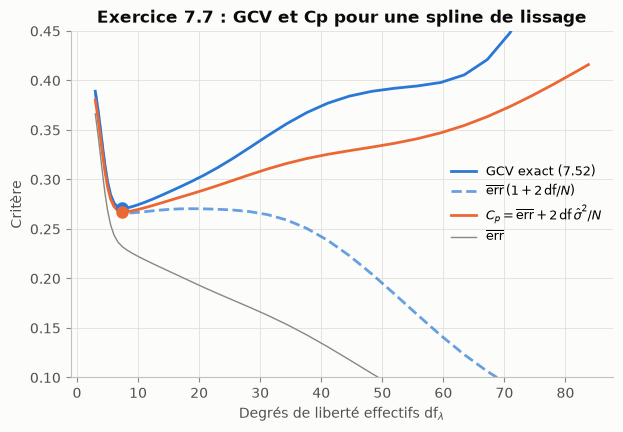

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(dfs, gcv, color=BLUE, label="GCV exact (7.52)")
ax.plot(dfs, approx, "--", color=BLUE, alpha=0.7, label=r"$\overline{\mathrm{err}}\,(1 + 2\,\mathrm{df}/N)$")
ax.plot(dfs, cp, color=ORANGE, label=r"$C_p = \overline{\mathrm{err}} + 2\,\mathrm{df}\,\hat\sigma^2/N$")
ax.plot(dfs, errs, color=GRAY, lw=1, label=r"$\overline{\mathrm{err}}$")
for crit, c in [(gcv, BLUE), (cp, ORANGE)]:
    ax.plot(dfs[crit.argmin()], crit.min(), "o", color=c, ms=8)
ax.set_ylim(0.1, 0.45)
ax.set_xlabel(r"Degrés de liberté effectifs $\mathrm{df}_\lambda$")
ax.set_ylabel("Critère")
ax.set_title("Exercice 7.7 : GCV et Cp pour une spline de lissage")
ax.legend()
plt.show()

Pour des df modérés, GCV, son approximation et $C_p$ sont très proches et désignent des
lissages voisins (points). Quand $\mathrm{df}/N$ grandit, l'approximation linéaire décroche
de GCV, et $C_p$ et GCV divergent car $\overline{\mathrm{err}}$ n'estime plus bien
$\sigma^2_\varepsilon$.

> **À retenir.** Au premier ordre en $\mathrm{df}/N$,
> $\mathrm{GCV}\approx\overline{\mathrm{err}} + 2\frac{\mathrm{df}}N\overline{\mathrm{err}}$ :
> c'est $C_p$/AIC où la variance du bruit est estimée par l'erreur d'apprentissage du
> modèle courant au lieu de celle d'un modèle de référence peu biaisé.

## Exercice 7.8 : La famille $I(\sin(\alpha x) > 0)$ a une dimension VC infinie

**Énoncé.** Montrer que l'ensemble de fonctions $\{I(\sin(\alpha x) > 0)\}$ pulvérise les
points $z_1 = 10^{-1}, \dots, z_\ell = 10^{-\ell}$ de la droite réelle, pour tout $\ell$.
En déduire que la dimension VC de cette classe est infinie.

**Rappels.** Pulvériser $\{z_1, \dots, z_\ell\}$ signifie : pour **chacun** des $2^\ell$
étiquetages $(y_1, \dots, y_\ell)\in\{0,1\}^\ell$, il existe $\alpha$ tel que
$I(\sin(\alpha z_j) > 0) = y_j$ pour tout $j$. On utilise que $\sin t > 0$ si et seulement
si $t \bmod 2\pi\in\,]0, \pi[$, autrement dit si $t/\pi \bmod 2\in\,]0, 1[$.

**Construction.** Étant donné l'étiquetage, on pose

$$\alpha = \pi\Big(1 + \sum_{i=1}^\ell(1 - y_i)\,10^{i}\Big).$$

Fixons $j$ et calculons $\alpha z_j/\pi = 10^{-j} + \sum_{i=1}^\ell(1 - y_i)10^{i-j}$. On
sépare la somme en trois parties :

* $i > j$ : $10^{i-j}$ est un entier **pair** (multiple de 10), donc ces termes ne changent
  pas $\alpha z_j/\pi$ modulo 2 ;
* $i = j$ : le terme vaut $(1 - y_j)\in\{0, 1\}$ ;
* $i < j$ (avec le terme $10^{-j}$) : leur somme
  $\varepsilon_j = 10^{-j} + \sum_{i<j}(1 - y_i)10^{i-j}$ vérifie
  $0 < \varepsilon_j\leq\sum_{m=1}^{\infty}10^{-m} = 1/9 < 1$.

Ainsi $\alpha z_j/\pi\equiv(1 - y_j) + \varepsilon_j\pmod 2$ avec $\varepsilon_j\in\,]0, 1[$ :

* si $y_j = 1$ : $\alpha z_j/\pi\equiv\varepsilon_j\in\,]0, 1[$, donc $\sin(\alpha z_j) > 0$ et
  l'indicatrice vaut $1$ ;
* si $y_j = 0$ : $\alpha z_j/\pi\equiv 1 + \varepsilon_j\in\,]1, 2[$, donc $\sin(\alpha z_j) < 0$
  et l'indicatrice vaut $0$.

Tout étiquetage est donc réalisé : les $\ell$ points sont pulvérisés. Comme c'est vrai pour
**tout** $\ell$, aucun entier ne majore le nombre de points pulvérisables : la dimension
VC est infinie, bien que la classe n'ait qu'**un seul** paramètre. $\square$

**Vérification numérique.** Pour de grands $\ell$, $\alpha\approx 10^\ell$ et le calcul de
$\sin(\alpha z_j)$ en flottants perd toute précision. On calcule donc les phases
$\alpha z_j/\pi\bmod 2$ en **arithmétique rationnelle exacte** (`sel.sin_shatter_phases`),
et l'on vérifie tous les étiquetages pour $\ell\leq 12$ ($2^{12} = 4096$ étiquetages).

In [6]:
import itertools
for l in [1, 2, 4, 8, 12]:
    ok = all(np.array_equal(((ph := sel.sin_shatter_phases(lab)) > 0) & (ph < 1), np.array(lab, bool))
             for lab in itertools.product([0, 1], repeat=l))
    print("l = %2d : les %5d étiquetages sont réalisés : %s" % (l, 2 ** l, ok))
rng = np.random.RandomState(0)
lab40 = rng.randint(0, 2, 40)
ph = sel.sin_shatter_phases(lab40)
print("l = 40, étiquetage aléatoire réalisé :", np.array_equal((ph > 0) & (ph < 1), lab40.astype(bool)))

l =  1 : les     2 étiquetages sont réalisés : True
l =  2 : les     4 étiquetages sont réalisés : True
l =  4 : les    16 étiquetages sont réalisés : True
l =  8 : les   256 étiquetages sont réalisés : True
l = 12 : les  4096 étiquetages sont réalisés : True
l = 40, étiquetage aléatoire réalisé : True


Visualisons un exemple avec $\ell = 3$ et l'étiquetage $(y_1, y_2, y_3) = (1, 0, 1)$ : on
trouve $\alpha = \pi(1 + 10^2) = 101\pi$. On trace $\sin(\alpha x)$ en échelle logarithmique
en $x$ pour voir les trois points.

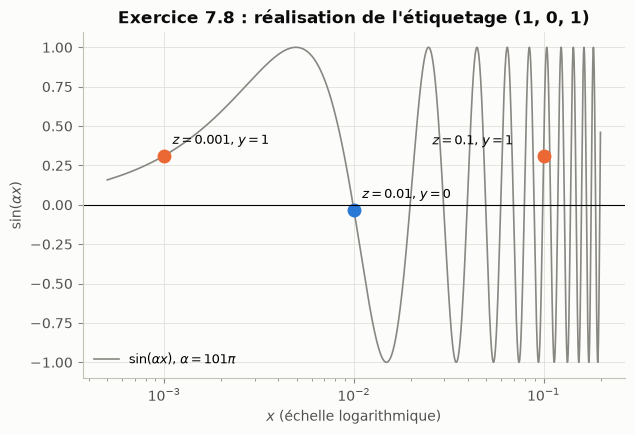

In [7]:
lab = [1, 0, 1]
alpha = sel.sin_shatter_alpha(lab)
z = 10.0 ** -np.arange(1, 4)
xx = np.logspace(-3.3, -0.7, 4000)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(xx, np.sin(alpha * xx), color=GRAY, lw=1.2, label=r"$\sin(\alpha x)$, $\alpha = 101\pi$")
for zj, yj in zip(z, lab):
    ax.plot(zj, np.sin(alpha * zj), "o", ms=9, color=ORANGE if yj else BLUE,
            label=None)
    ax.annotate("$z=%g$, $y=%d$" % (zj, yj), (zj, np.sin(alpha * zj)), xytext=(-80 if zj > 0.05 else 6, 8),
                textcoords="offset points", fontsize=9)
ax.axhline(0, color="k", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("$x$ (échelle logarithmique)")
ax.set_ylabel(r"$\sin(\alpha x)$")
ax.set_title("Exercice 7.8 : réalisation de l'étiquetage (1, 0, 1)")
ax.legend(loc="lower left")
plt.show()

> **Remarque.** La dimension VC est définie avec la configuration de points **la plus
> favorable** : il existe des ensembles de 4 points que cette classe ne pulvérise pas (par
> exemple des points régulièrement espacés), mais cela n'empêche pas la dimension d'être
> infinie.

> **À retenir.** Le nombre de paramètres n'est pas une bonne mesure de complexité :
> $I(\sin(\alpha x) > 0)$ n'a qu'un paramètre mais une dimension VC infinie, en choisissant
> la fréquence $\alpha = \pi(1 + \sum_i(1 - y_i)10^i)$ on réalise tout étiquetage des points
> $10^{-i}$.

## Exercice 7.9 : Meilleur sous-ensemble sur les données de la prostate

**Énoncé.** Pour les données de cancer de la prostate du chapitre 3, mener une régression
linéaire par meilleur sous-ensemble, comme dans la table 3.3 (troisième colonne). Calculer
les estimations de l'erreur de prédiction par AIC, BIC, validation croisée à 5 et à 10
blocs et bootstrap .632. Discuter les résultats.

**Données et rappels.** La réponse est `lpsa` (log de l'antigène prostatique) et il y a
8 prédicteurs. On utilise la séparation du livre : 67 observations d'apprentissage et 30
de test ; comme au chapitre 3, les prédicteurs sont **standardisés** (moyenne et écart-type
de l'échantillon d'apprentissage). Pour chaque taille $k = 0, \dots, 8$, le meilleur
sous-ensemble est celui de plus petite somme des carrés résiduels parmi les
$\binom 8k$ possibles (`sel.best_subset`, recherche exhaustive sur $2^8 = 256$ modèles).

In [8]:
pr = datasets.load_prostate()
names = ["lcavol", "lweight", "age", "lbph", "svi", "lcp", "gleason", "pgg45"]
tr = pr["train"].to_numpy()
Xall = pr[names].to_numpy(float)
mu, sd = Xall[tr].mean(0), Xall[tr].std(0, ddof=1)
Xall = (Xall - mu) / sd
yall = pr["lpsa"].to_numpy(float)
X, y, Xt, yt = Xall[tr], yall[tr], Xall[~tr], yall[~tr]
N = len(y)
bs = sel.best_subset(X, y)
for k, (cols, r) in enumerate(bs):
    print("k = %d  RSS = %6.2f  variables : %s" % (k, r, ", ".join(names[c] for c in cols)))

k = 0  RSS =  96.28  variables : 
k = 1  RSS =  44.53  variables : lcavol
k = 2  RSS =  37.09  variables : lcavol, lweight
k = 3  RSS =  34.91  variables : lcavol, lweight, svi
k = 4  RSS =  32.81  variables : lcavol, lweight, lbph, svi
k = 5  RSS =  32.07  variables : lcavol, lweight, lbph, svi, pgg45
k = 6  RSS =  30.54  variables : lcavol, lweight, lbph, svi, lcp, pgg45
k = 7  RSS =  29.44  variables : lcavol, lweight, age, lbph, svi, lcp, pgg45
k = 8  RSS =  29.43  variables : lcavol, lweight, age, lbph, svi, lcp, gleason, pgg45


**Critères analytiques.** Avec $d = k + 1$ paramètres (constante comprise),
$\overline{\mathrm{err}}_k = \mathrm{RSS}_k/N$ et $\hat\sigma^2_\varepsilon = \mathrm{RSS}_8/(N - 9)$
estimé sur le modèle complet (peu biaisé) :
$$\mathrm{AIC}_k = \overline{\mathrm{err}}_k + 2\frac dN\hat\sigma^2_\varepsilon,\qquad
\mathrm{BIC}_k\cdot\frac{\hat\sigma^2_\varepsilon}N = \overline{\mathrm{err}}_k + (\log N)\frac dN\hat\sigma^2_\varepsilon.$$
On divise le BIC par $N/\hat\sigma^2_\varepsilon$ pour l'exprimer à la même échelle que
l'erreur quadratique (cela ne change pas son minimiseur).

> **Remarque.** Ces formules ignorent que le sous-ensemble a été **choisi** sur les données :
> comme on l'a vu au cours 2, le vrai nombre effectif de paramètres dépasse alors $k + 1$.

In [9]:
ks = np.arange(9)
d = ks + 1
err = np.array([r for _, r in bs]) / N
s2 = bs[-1][1] / (N - 9)
aic = sel.cp_statistic(err, d, s2, N)
bic = sel.bic_gaussian(err, d, s2, N) * s2 / N
test = np.array([np.mean((yt - sel.ols_fit_predict(X[:, list(c)], y, Xt[:, list(c)])) ** 2) if c
                 else np.mean((yt - y.mean()) ** 2) for c, _ in bs])
print("sigma^2 estimé : %.3f" % s2)

sigma^2 estimé : 0.507


**Validation croisée et bootstrap - de la bonne manière.** La procédure évaluée pour une
taille $k$ est « choisir le meilleur sous-ensemble de taille $k$, puis l'ajuster » : la
**recherche exhaustive est refaite** dans chaque bloc et dans chaque échantillon bootstrap
(section 7.10.2). Une seule fonction calcule les prédictions des 9 tailles à la fois.

In [10]:
def subset_path(Xa, ya, Xb):
    """Prédictions en Xb du meilleur sous-ensemble de chaque taille k = 0..8 ajusté sur (Xa, ya)."""
    out = []
    for cols, _ in sel.best_subset(Xa, ya):
        cols = list(cols)
        out.append(sel.ols_fit_predict(Xa[:, cols], ya, Xb[:, cols]) if cols else np.full(len(Xb), ya.mean()))
    return np.array(out)

def cv_path(K, rng):
    folds = sel.kfold_indices(N, K, rng)
    fold_err = np.zeros((K, 9))
    for f_, te in enumerate(folds):
        trn = np.setdiff1d(np.arange(N), te)
        fold_err[f_] = ((subset_path(X[trn], y[trn], X[te]) - y[te]) ** 2).mean(1)
    sizes = np.array([len(t) for t in folds])
    cv = (fold_err * sizes[:, None]).sum(0) / N
    return cv, fold_err.std(0, ddof=1) / np.sqrt(K)

rng = np.random.RandomState(0)
cv5, se5 = cv_path(5, rng)
cv10, se10 = cv_path(10, rng)

Pour le bootstrap .632 (éq. (7.56)-(7.57)), on tire $B = 100$ échantillons bootstrap ; pour
chaque observation $i$, on moyenne les pertes des modèles ajustés sur les échantillons
qui ne la contiennent pas, puis
$\widehat{\mathrm{Err}}^{(.632)} = 0{,}368\,\overline{\mathrm{err}} + 0{,}632\,\widehat{\mathrm{Err}}^{(1)}$.

In [11]:
B = 100
loss_sum = np.zeros((9, N))
cnt = np.zeros(N)
for b in range(B):
    idx = rng.randint(0, N, N)
    out = np.setdiff1d(np.arange(N), idx)
    loss_sum[:, out] += (subset_path(X[idx], y[idx], X[out]) - y[out]) ** 2
    cnt[out] += 1
loo1 = (loss_sum[:, cnt > 0] / cnt[cnt > 0]).mean(1)
boot632 = 0.368 * err + 0.632 * loo1

In [12]:
tab = pd.DataFrame({"err (appr.)": err, "AIC": aic, "BIC (échelle err)": bic,
                    "CV 5 blocs": cv5, "CV 10 blocs": cv10, "bootstrap .632": boot632,
                    "erreur test": test}, index=pd.Index(ks, name="taille k"))
tab.round(3)

,err (appr.),AIC,BIC (échelle err),CV 5 blocs,CV 10 blocs,bootstrap .632,erreur test
taille k,,,,,,,
0,1.437,1.452,1.469,1.469,1.523,1.481,1.057
1,0.665,0.695,0.728,0.698,0.708,0.718,0.480
2,0.554,0.599,0.649,0.663,0.605,0.661,0.492
3,0.521,0.582,0.648,0.692,0.684,0.661,0.401
4,0.490,0.566,0.649,0.718,0.571,0.650,0.456
5,0.479,0.570,0.670,0.726,0.649,0.641,0.486
6,0.456,0.562,0.679,0.684,0.594,0.622,0.549
7,0.439,0.561,0.694,0.643,0.545,0.594,0.517
8,0.439,0.576,0.726,0.656,0.559,0.591,0.521


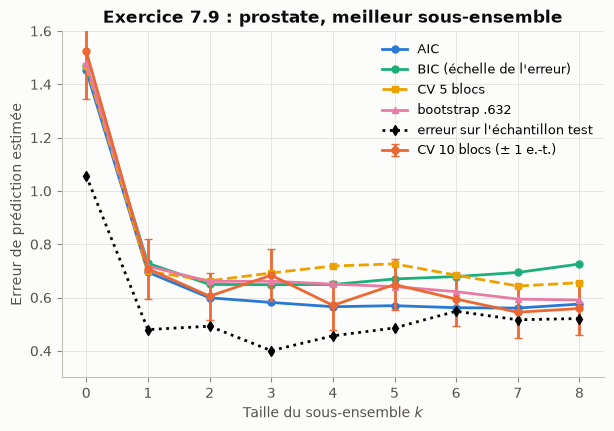

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ks, aic, "o-", color=BLUE, label="AIC")
ax.plot(ks, bic, "o-", color=COLORS[2], label="BIC (échelle de l'erreur)")
ax.errorbar(ks, cv10, yerr=se10, fmt="o-", color=ORANGE, capsize=3, label="CV 10 blocs ($\\pm$ 1 e.-t.)")
ax.plot(ks, cv5, "s--", color=COLORS[3], label="CV 5 blocs")
ax.plot(ks, boot632, "^-", color=COLORS[4], label="bootstrap .632")
ax.plot(ks, test, "d:", color="k", label="erreur sur l'échantillon test")
ax.set_ylim(0.3, 1.6)
ax.set_xlabel("Taille du sous-ensemble $k$")
ax.set_ylabel("Erreur de prédiction estimée")
ax.set_title("Exercice 7.9 : prostate, meilleur sous-ensemble")
ax.legend()
plt.show()

In [14]:
choice = {c: int(tab[c].idxmin()) for c in ["AIC", "BIC (échelle err)", "CV 5 blocs", "CV 10 blocs", "bootstrap .632", "erreur test"]}
i1 = int(np.argmin(cv10))
choice["CV 10 blocs, règle 1 e.-t."] = int(np.where(cv10 <= cv10[i1] + se10[i1])[0][0])
pd.Series(choice, name="taille choisie").to_frame()

,taille choisie
AIC,7
BIC (échelle err),3
CV 5 blocs,7
CV 10 blocs,7
bootstrap .632,8
erreur test,3
"CV 10 blocs, règle 1 e.-t.",2


La validation croisée dépend du découpage aléatoire en blocs. Répétons-la avec 20 découpages
différents pour mesurer cette variabilité.

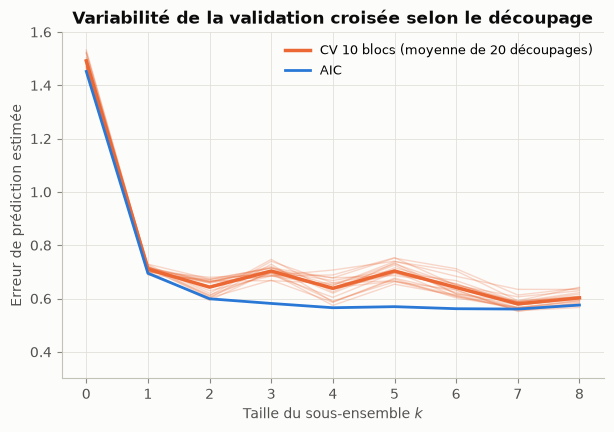

taille minimisant la CV, sur 20 découpages : [ 0  0  0  0  0  0  0 19  1]


In [15]:
reps = np.array([cv_path(10, np.random.RandomState(s))[0] for s in range(20)])
fig, ax = plt.subplots(figsize=(7, 4.5))
for r_ in reps:
    ax.plot(ks, r_, color=ORANGE, alpha=0.25, lw=1)
ax.plot(ks, reps.mean(0), color=ORANGE, lw=2.5, label="CV 10 blocs (moyenne de 20 découpages)")
ax.plot(ks, aic, color=BLUE, label="AIC")
ax.set_ylim(0.3, 1.6)
ax.set_xlabel("Taille du sous-ensemble $k$")
ax.set_ylabel("Erreur de prédiction estimée")
ax.set_title("Variabilité de la validation croisée selon le découpage")
ax.legend()
plt.show()
print("taille minimisant la CV, sur 20 découpages :", np.bincount(reps.argmin(1), minlength=9))

**Discussion.**

* Toutes les méthodes s'accordent sur l'essentiel : le modèle constant ($k = 0$) et le
  modèle à une seule variable (`lcavol`) sont nettement moins bons ; à partir de $k = 2$
  les courbes deviennent **très plates**, et les écarts entre les tailles $2$ à $8$ sont de
  l'ordre d'une erreur-type de la validation croisée (environ $0{,}1$).
* Les minimiseurs diffèrent : AIC et la validation croisée (5 et 10 blocs) retiennent un
  grand modèle ($k = 7$), le bootstrap .632 le modèle complet, le BIC - qui pénalise
  davantage ($\log 67\approx 4{,}2$ au lieu de $2$) - un modèle à 3 variables, et la **règle
  « un écart-type »** le modèle à 2 variables (`lcavol`, `lweight`) de la table 3.3.
* Le bootstrap .632 décroît presque régulièrement avec $k$ : son poids $0{,}368$ sur
  $\overline{\mathrm{err}}$, qui décroît toujours, le pousse vers les grands modèles.
* Les estimations par validation croisée sont un peu plus élevées que l'AIC : elles
  évaluent des modèles ajustés sur moins de données **et** incluent le coût de la recherche
  du meilleur sous-ensemble, que l'AIC ignore (il compte $k + 1$ paramètres).
* Ici le minimiseur de la CV à 10 blocs est stable d'un découpage à l'autre, mais la courbe
  elle-même fluctue d'environ $\pm 0{,}05$ selon le découpage, soit autant que les écarts
  entre modèles.
* L'erreur sur l'échantillon test, calculée sur 30 observations seulement, est elle aussi
  très bruitée (minimum en $k = 3$, mais des écarts de l'ordre de $0{,}1$ entre tailles
  voisines) : elle ne permet pas de trancher nettement non plus.

> **À retenir.** Sur un petit jeu de données, les estimateurs de l'erreur donnent des
> courbes plates et bruitées : le choix précis de la taille est fragile, et il est
> raisonnable de privilégier un modèle simple (règle un écart-type, BIC). Pour la validation
> croisée et le bootstrap, la **sélection** du sous-ensemble doit être refaite à chaque
> ajustement.

## Exercice 7.10 : Validation croisée avec des prédicteurs binaires

**Énoncé.** On reprend l'exemple de la section 7.10.3 ($N = 20$ observations en deux
classes égales, $p$ prédicteurs indépendants des classes, classifieur « souche » à une
seule coupure), mais avec des prédicteurs **binaires**, de sorte qu'il n'y a pas de seuil
à estimer. Si $p$ est très grand, on trouvera probablement un prédicteur qui sépare
parfaitement l'échantillon d'apprentissage complet, donc qui séparera parfaitement aussi
chaque bloc de validation (un cinquième des données) : son erreur de validation croisée
serait nulle. Cela signifie-t-il que la validation croisée n'estime pas correctement
l'erreur de test dans cette situation ?

**Mise en équations.** Un prédicteur binaire $x_j\in\{0,1\}$ définit deux règles :
$\hat G = x_j$ ou $\hat G = 1 - x_j$. La souche choisit le prédicteur et la règle de plus
petite erreur d'apprentissage. Comme les $x_{ij}$ sont des tirages indépendants de loi
$\mathcal B(1/2)$, indépendants des classes, un prédicteur donné sépare parfaitement $n$
observations avec probabilité $2\cdot 2^{-n}$ (l'une des deux règles est parfaite). Le
nombre **moyen** de prédicteurs parfaits vaut donc

$$\mathbb E[\#\text{parfaits sur } n\text{ points}] = p\cdot 2^{1-n}.$$

Avec $p = 2^{20}\approx 10^6$ et $N = 20$ : environ $2$ prédicteurs parfaits sur les 20
observations, mais environ $p\cdot 2^{-15} = 32$ prédicteurs parfaits sur les $16$
observations d'apprentissage d'un bloc.

**Réponse : non.** L'argument suppose implicitement qu'on utilise, dans chaque bloc, le
prédicteur choisi sur **toutes** les données. Mais une validation croisée correcte
**refait toute la procédure** sur les 16 observations d'apprentissage du bloc, y compris le
choix du prédicteur. Sur 16 observations, il y a typiquement une trentaine de prédicteurs
parfaits ; celui qui est retenu (au hasard parmi les ex æquo, ou le premier dans l'ordre)
n'a **aucune raison** d'être celui qui sépare aussi les 4 observations du bloc : sur ces 4
observations, il se trompe en moyenne une fois sur deux.

La validation croisée estime donc une erreur proche de $50\,\%$, ce qui est la **vraie**
erreur de test de la procédure (et même celle du prédicteur parfait sur les 20 points,
qui n'a aucun lien réel avec la classe). Seule la « mauvaise » validation croisée, qui
fige le prédicteur choisi sur toutes les données, donnerait une erreur nulle. Petite
nuance : le prédicteur globalement parfait figure parmi les prédicteurs parfaits de chaque
bloc ; s'il est choisi, il prédit bien le bloc, d'où une estimation très légèrement
inférieure à $50\,\%$ (biais de l'ordre de $1/32$ de l'écart).